# Examples: Protocolls in QQ

Following are a few algorithms / protocolls. They mostly follow the class of Johannes Kofler "Quantum Information" SS2026, but implementation may not be included. For these cases, sources have been added at the algorithm.

In [13]:
import numpy as np
import quickqudits as qq
import random as rnd

# Deutsch Algorithm Demo

This is a Demo for the Deutsch Algorithm.  \
Drawing can be enabled or disabled via the boolean flag. \
It returns wheter or not a function was balanced (False -> constant, Ture -> balanced). \
Implementation according to Basic Quantum Algorithms by Renato Portugal.

In [14]:
def deutschAlg(p0, p1, drawflag=False) -> bool:
    dqc = qq.QuantumCircuit(2, 2, "Deutsch-Algorithm")
    
    # implementation according to https://arxiv.org/pdf/2201.10574{0: 0}
    def deutschOracle(fx0, fx1):
        # constant function 0
        if(fx0 == 0 and fx0 == fx1):
            dqc.insert(gate=qq.I_gate, qudits=(0, ), column=2)
            dqc.insert(gate=qq.I_gate, qudits=(1, ), column=2)
        #balanced function 01
        elif(fx0 == 0 and fx0 != fx1):
            dqc.insert(gate=qq.CNOT_gate, qudits=(0,1), column=2)
        #balanced function 10
        elif(fx0 == 1 and fx0 != fx1):
            dqc.insert(gate=qq.X_gate, qudits=(0, ), column=2)
            dqc.insert(gate=qq.CNOT_gate, qudits=(0,1), column=3)
            dqc.insert(gate=qq.X_gate, qudits=(0, ), column=4)
        #constant function 1
        elif(fx0 == 1 and fx0 == fx1):
            dqc.insert(gate=qq.X_gate, qudits=(0, ), column=2)
            dqc.insert(gate=qq.CNOT_gate, qudits=(0,1), column=3)
            dqc.insert(gate=qq.X_gate, qudits=(0, ), column=4)
            dqc.insert(gate=qq.CNOT_gate, qudits=(0,1), column=5)
    
    dqc.I(0)
    dqc.H(0)
    dqc.X(1)
    dqc.H(1)
    deutschOracle(p0, p1)
    dqc.H(0)
    dqc.measure(0)

    if(drawflag):
            dqc.draw()
    
    psi, res = dqc.execute(print_state=False)
    return res[0]
    

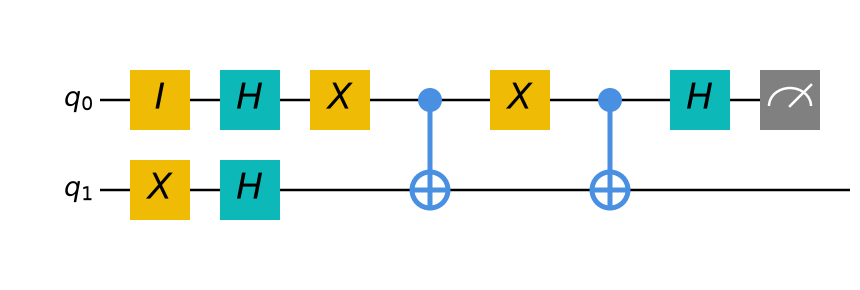

Function was constant and correct
p0 = 1, p1 = 1, res = 0


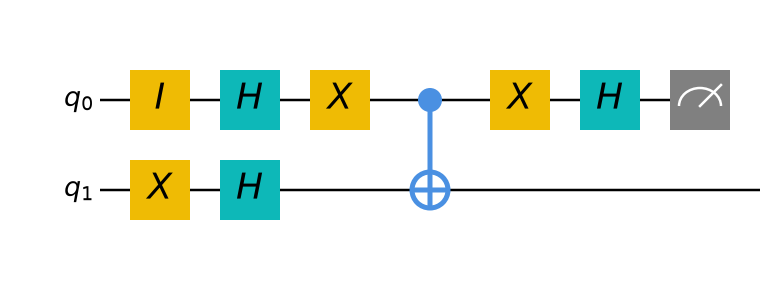

Function was balanced and correct
p0 = 1, p1 = 0, res = 1


In [20]:
for i in range(2):
    p0 = rnd.randrange(0, 2, 1)
    p1 = rnd.randrange(0, 2, 1)
    check = deutschAlg(p0, p1, True)
    
    if (p0 == p1 and check == 0):
        print("Function was constant and correct")
    elif (p0 != p1 and check == 1):
        print("Function was balanced and correct")
    else:
        print("An error occured")
    print(f"p0 = {p0}, p1 = {p1}, res = {check}")

# Superdense Coding
Use the draw- and printflag accordingly. \
Implementation according to Quantum Information (2026) by Johannes Kofler


In [16]:
def superdenseCoding(p0, p1, drawflag=False, printflag=False):
    sc = qq.QuantumCircuit(2, 2, "Teleportation")
    
    # Charlie
    sc.H(0)
    sc.CNOT(0, 1)
    
    # alice
    aliceEncoding(p0, p1, sc)
    
    # bob
    sc.CNOT(0, 1)
    sc.H(0)
    sc.measure_all()
    psi, res = sc.execute(print_state=printflag)
    
    if drawflag:
        sc.draw()

def aliceEncoding(m0, m1, sc):
    if (m0 == m1 and m0 == 0):
        sc.I(0)
    elif (m0 == m1 and m0 == 1):
        sc.Z(0)
        sc.X(0)
    elif (m0 != m1 and m0 == 0):
        sc.X(0)
    elif (m0 != m1 and m0 == 1):
        sc.Z(0)

In [17]:
for i in range(2):
    p0 = rnd.randrange(0, 2, 1)
    p1 = rnd.randrange(0, 2, 1)
    superdenseCoding(p0, p1, False, False)


# Teleportation
Qubit 0: Ebit Alice \
Qubit 1: Ebit Bob \
Qubit 2: Unknown Qubit \
In this implementation, stabilizer tableaus are used for measurements, as they allow for time dependent measurements. \
Applying a QuantumCircuit and extending it after measurement is not sufficient for QuantumTeleportation. \
Implementation according to Quantum Information (2026) by Johannes Kofler


In [18]:
def TeleportationGlobal(drawflag=False):
    qcT = qq.QuantumCircuit(3, 2, "Teleportation")

    # shared entangled bits
    qcT.H(0)
    qcT.CNOT(0, 1)

    # unknown psi which will be transmitted    
    randPsi = rnd.randrange(0, 4, 1)

    init = randPsi
    
    if randPsi == 0:
        qcT.I(2)        
    elif randPsi == 1:
        qcT.X(2)
    elif randPsi == 2:
        qcT.H(2)
    elif randPsi == 3:
        qcT.X(2)
        qcT.H(2)

    # entangle alice ebit with unknown psi
    aliceTeleportation(qcT)
    
    # measure 
    tab = qq.Tableau(3, 2, full=True)
    tab.apply_circuit(qcT)
    post_tab, post_result = tab.post_measure(qudits_to_measure=(0, 2), seed=22)
    
    # send the measurement to bob so he can correct his ebit to psi    
    bobTeleportation(post_tab, post_result, init, drawflag, qcT)
    
def aliceTeleportation(qcT):
    qcT.CNOT(2, 0)
    qcT.H(2)
    
def bobTeleportation(tab, res, init, drawflag, qcT):
    temp = qq.QuantumCircuit(1, 2)
    if res[0] == 1:
        temp.X(0)
    if res[2] == 1:
        temp.Z(0)
    tab.apply_circuit(temp)
    print(init)
    print(tab.to_statevector())
    if drawflag:
        qcT.draw()

0
[1.+0.j 0.+0.j]


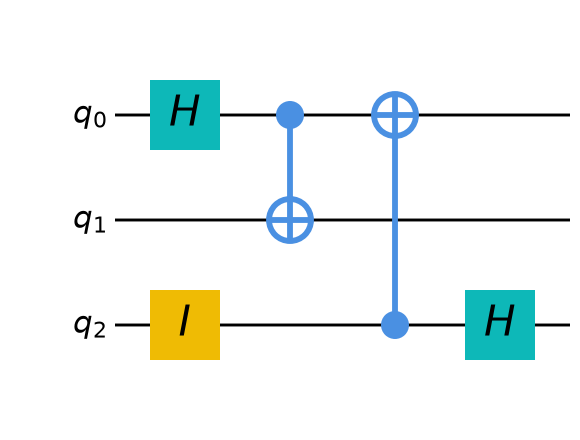

1
[0.+0.j 1.+0.j]


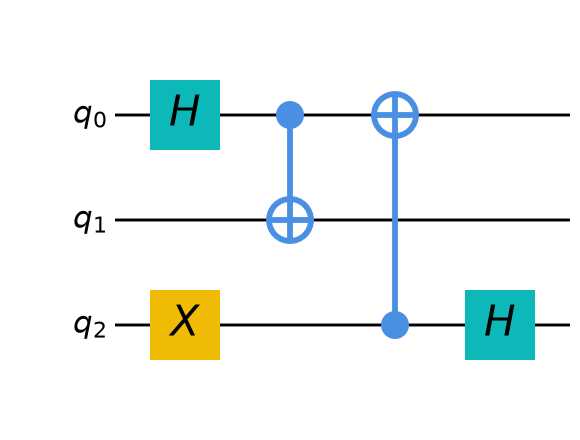

In [19]:
for i in range(2):
    TeleportationGlobal(True)